# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Catacombs666/ML_int-/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:
1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

**Author: Majhabul Hoque**


## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally it just moves to the repo root.

In [1]:
import os, sys, subprocess, json
from pathlib import Path
candidates=[Path.cwd(),*Path.cwd().parents,Path('/content/ML_int-')]
ROOT=next((p for p in candidates if (p/'data/raw/content_refresh_anonymized.csv').exists()),None)
if ROOT is None:
    ROOT=Path('/content/ML_int-') if Path('/content').exists() else Path.cwd()/'ML_int-'
    subprocess.run(['git','clone','https://github.com/Catacombs666/ML_int-.git',str(ROOT)],check=True)
os.chdir(ROOT)
if os.environ.get('CAPSTONE_OFFLINE')!='1':
    subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements.txt'],check=True)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype']='none'
df=pd.read_csv('data/raw/content_refresh_anonymized.csv')
df['is_declining_label']=df['trend_direction'].str.lower().eq('down').astype(int)
print('Starter shape:',df.drop(columns=['is_declining_label']).shape,'| Declining proxy rate:',round(df.is_declining_label.mean(),4))
print('Author: Majhabul Hoque | no client records printed')


Starter shape: (30000, 44) | Declining proxy rate: 0.5421
Author: Majhabul Hoque | no client records printed


## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

In [2]:
result=subprocess.run([sys.executable,'scripts/run_all.py'],capture_output=True,text=True,check=True)
print(result.stdout)


▶ Step 1/5 — Prepare features — clean the data, build the feature vector, define the label
Prepared 30,000 rows from 30,000 raw rows
Wrote /workspace/scratch/ebaea427ecb2/capstone-repo/data/processed/refresh_feature_vector.csv

▶ Step 2/5 — Baseline — a transparent hand-written rule to beat
Wrote baseline queue: /workspace/scratch/ebaea427ecb2/capstone-repo/data/processed/baseline_refresh_queue.csv
Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340

▶ Step 3/5 — Train — logistic regression, decision tree, random forest (client-holdout split)
Trained 3 models on 30,000 rows
Split strategy: client_holdout
Best model: random_forest
Wrote predictions: /workspace/scratch/ebaea427ecb2/capstone-repo/data/processed/model_predictions.csv
Wrote model results: /workspace/scratch/ebaea427ecb2/capstone-repo/outputs/model_results.json

▶ Step 4/5 — Evaluate — ranked refresh queue, charts, and the Markdown report
Wrote final refresh queue: /workspace/scratch/ebaea427ecb

### What just happened?
The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

In [3]:
import json
res = json.load(open("outputs/model_results.json"))

base = res["baseline"]["baseline_precision_at_50"]
rf   = res["models"]["random_forest"]["precision_at_50"]

print(f"Hand-written rule  Precision@50: {base:.3f}   (~{round(base*50)} of the top 50 right)")
print(f"Random forest      Precision@50: {rf:.3f}   (~{round(rf*50)} of the top 50 right)")
print(f"\nThe learned model roughly {rf/base:.1f}x the rule on this metric.")
print("Validation split used:", res["split_strategy"], "(pages from a client are never in both train and test)")

Hand-written rule  Precision@50: 0.240   (~12 of the top 50 right)
Random forest      Precision@50: 0.740   (~37 of the top 50 right)

The learned model roughly 3.1x the rule on this metric.
Validation split used: client_holdout (pages from a client are never in both train and test)


You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the *shape* of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they *are* the core lesson. Run the three cells below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

In [4]:
print('Raw rows:',len(df),'| Clients:',df.client_id.nunique(),'| Duplicate content:',df.content_id.duplicated().sum())
print(df[['impressions_90d','clicks_90d','avg_position']].describe().round(3).to_string())

Raw rows: 30000 | Clients: 32 | Duplicate content: 0
       impressions_90d  clicks_90d  avg_position
count        30000.000   30000.000     30000.000
mean          5200.366      16.097        16.342
std          16838.020      75.077        15.217
min              1.000       0.000         0.000
25%             81.000       0.000         6.200
50%            731.000       1.000        10.800
75%           3615.250       7.000        22.300
max         517715.000    4178.000       245.000


### Discovery A — "High search volume means more traffic." Does it?

In [5]:
corr = df["search_volume"].corr(df["impressions_90d"])
print(f"Correlation between search_volume and impressions_90d: {corr:.3f}")
print("Near zero -> keyword search volume barely predicts the traffic a page actually gets.")

Correlation between search_volume and impressions_90d: 0.001
Near zero -> keyword search volume barely predicts the traffic a page actually gets.


### Discovery B — the CTR cliff by position
Click-through rate is not flat: it collapses as you move down the results.

position_tier
page_1      0.3548
top_3       0.3341
striking    0.2558
page_3_5    0.1424
deep        0.0554


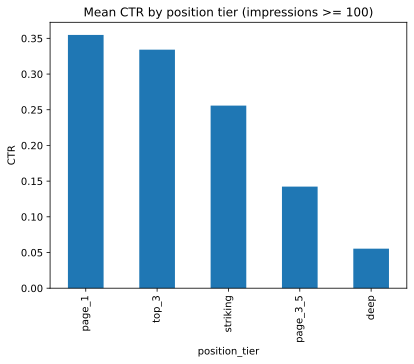

In [6]:
visible = df[df["impressions_90d"] >= 100]
ctr_by_pos = visible.groupby("position_tier")["ctr"].mean().sort_values(ascending=False)
print(ctr_by_pos.round(4).to_string())
ctr_by_pos.plot(kind="bar", title="Mean CTR by position tier (impressions >= 100)", ylabel="CTR");

### Discovery C — is longer content the lever?
Compare word count for **declining** vs **growing** pages.

In [7]:
wc = df.groupby("trend_direction")["word_count"].median()
print(wc.round(0).to_string())
print('Similar observed medians do not establish whether editing length changes traffic.')

trend_direction
down      2909.0
flat      2698.0
new       2239.0
stable    2912.0
up        2848.0
Similar observed medians do not establish whether editing length changes traffic.


## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR *at the same position tier*?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as *observed / directional* — never "I proved Google's algorithm." Keep client data out of anything you publish.

**Completed experiment:** compare impression-weighted CTR by content type within position tier, with a 500-impression floor and at least 30 pages per stratum. The executed table and chart below report the observed pattern.


position_tier       content_type  pages  weighted_ctr_pct
         deep    keyword article    383            0.0369
       page_1 comparison article     50            0.0425
       page_1    keyword article   6931            0.3498
       page_1     feedly article     83            0.4331
     page_3_5    keyword article   4307            0.1550
     striking     feedly article     34            0.2288
     striking    keyword article   4440            0.3496
        top_3    keyword article    455            0.4853
Observed: compare content types within position strata; differences are associations, not causal content effects.
Filter is >=500 impressions and positive measured position; each displayed stratum has >=30 pages.


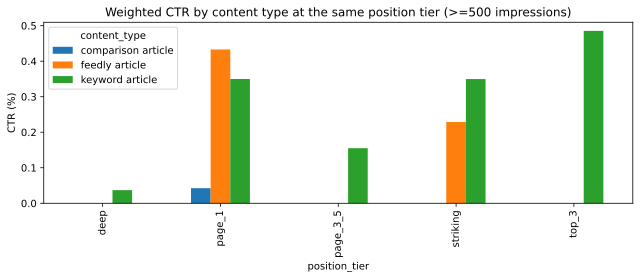

In [8]:
visible=df[(df.impressions_90d>=500)&(df.avg_position>0)].copy()
summary=visible.groupby(['position_tier','content_type'],observed=True).agg(pages=('content_id','size'),clicks=('clicks_90d','sum'),impressions=('impressions_90d','sum')).reset_index()
summary=summary[summary.pages>=30].copy()
summary['weighted_ctr_pct']=100*summary.clicks/summary.impressions
print(summary[['position_tier','content_type','pages','weighted_ctr_pct']].sort_values(['position_tier','weighted_ctr_pct']).round(4).to_string(index=False))
print('Observed: compare content types within position strata; differences are associations, not causal content effects.')
print('Filter is >=500 impressions and positive measured position; each displayed stratum has >=30 pages.')
summary.pivot(index='position_tier',columns='content_type',values='weighted_ctr_pct').plot(kind='bar',figsize=(9,4),title='Weighted CTR by content type at the same position tier (>=500 impressions)',ylabel='CTR (%)')
plt.tight_layout()


### Save your work
**Colab:** *File → Save a copy in GitHub* (writes to your own repo — that's your submission) and *File → Save a copy in Drive* (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.